In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv(r'C:\Users\tchin\Downloads\total_cases.csv')
df

,date,World,Afghanistan,Africa,Albania,Algeria,American Samoa,Andorra,Angola,Anguilla,...,Uruguay,Uzbekistan,Vanuatu,Vatican,Venezuela,Vietnam,Wallis and Futuna,Yemen,Zambia,Zimbabwe
0,2020-01-05,2,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2020-01-06,2,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2020-01-07,2,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,2020-01-08,2,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2020-01-09,2,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1669,2024-07-31,775819614,235214,13145344,335047,272121,8359,48015,107481,3904,...,1041331,175081,12019,26,552695,11624000,3760,11945,349824,266386
1670,2024-08-01,775819614,235214,13145344,335047,272121,8359,48015,107481,3904,...,1041331,175081,12019,26,552695,11624000,3760,11945,349824,266386
1671,2024-08-02,775819614,235214,13145344,335047,272121,8359,48015,107481,3904,...,1041331,175081,12019,26,552695,11624000,3760,11945,349824,266386
1672,2024-08-03,775819614,235214,13145344,335047,272121,8359,48015,107481,3904,...,1041331,175081,12019,26,552695,11624000,3760,11945,349824,266386


In [2]:
df['United States']

0               0
1               0
2               0
3               0
4               0
          ...    
1669    103436829
1670    103436829
1671    103436829
1672    103436829
1673    103436829
Name: United States, Length: 1674, dtype: int64

In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
World,1674.0,4.275371e+08,3.081441e+08,2.0,110747235.0,503419024.0,766875788.0,775866783.0
Afghanistan,1674.0,1.469468e+05,8.197695e+04,0.0,55604.0,178387.0,222526.0,235214.0
Africa,1674.0,8.731712e+06,5.079790e+06,0.0,3849558.0,12007437.0,13096529.0,13145380.0
Albania,1674.0,2.124463e+05,1.316913e+05,0.0,97909.0,274376.0,334090.0,335047.0
Algeria,1674.0,1.920136e+05,1.002381e+05,0.0,111764.0,265739.0,271841.0,272139.0
...,...,...,...,...,...,...,...,...
Vietnam,1674.0,6.122353e+06,5.524285e+06,0.0,2383.0,10432547.0,11617497.0,11624000.0
Wallis and Futuna,1674.0,1.570221e+03,1.615315e+03,0.0,9.0,454.0,3550.0,3760.0
Yemen,1674.0,8.347243e+03,4.599957e+03,0.0,2161.0,11817.0,11945.0,11945.0
Zambia,1674.0,2.231978e+05,1.416948e+05,0.0,73894.0,318467.0,345058.0,349842.0


In [4]:
df['date'] = pd.to_datetime(df['date'])

min_date = df['date'].min()
max_date = df['date'].max()
num_days = len(df)

# Check missing values across the dataframe
null_counts = df.isnull().sum()
total_nulls = null_counts.sum()

# Latest figures (most recent date)
latest_row = df.iloc[-1]
latest_date = latest_row['date'].strftime('%Y-%m-%d')

# Separate aggregates/regions from individual countries if possible, or top overall entities
# Aggregates in dataset:
aggregates = [
    'World', 'Africa', 'Asia', 'Europe', 'European Union (27)', 
    'High-income countries', 'Low-income countries', 'Lower-middle-income countries', 
    'Upper-middle-income countries', 'North America', 'Oceania', 'South America'
]

countries = [c for c in df.columns if c not in aggregates and c != 'date']

latest_world = latest_row['World']
latest_top10_countries = latest_row[countries].sort_values(ascending=False).head(10)
latest_regions = latest_row[[a for a in aggregates if a in df.columns]].sort_values(ascending=False)

print(f"Date range: {min_date.strftime('%Y-%m-%d')} to {max_date.strftime('%Y-%m-%d')} ({num_days} records)")
print(f"Total null values across dataset: {total_nulls}")
print(f"\nLatest Cumulative Cases as of {latest_date}:")
print(f"World Total: {latest_world:,}")
print("\nTop 10 Countries by Total Cumulative Cases:")
for country, count in latest_top10_countries.items():
    print(f"  {country}: {count:,}")

print("\nBy Income / Region Aggregates:")
for region, count in latest_regions.items():
    print(f"  {region}: {count:,}")

Date range: 2020-01-05 to 2024-08-04 (1674 records)
Total null values across dataset: 0

Latest Cumulative Cases as of 2024-08-04:
World Total: 775,866,783

Top 10 Countries by Total Cumulative Cases:
  United States: 103,436,829
  China: 99,373,219
  India: 45,041,748
  France: 38,997,490
  Germany: 38,437,756
  Brazil: 37,511,921
  South Korea: 34,571,873
  Japan: 33,803,572
  Italy: 26,781,078
  United Kingdom: 24,974,629

By Income / Region Aggregates:
  World: 775,866,783
  High-income countries: 429,044,049
  Asia: 301,499,099
  Europe: 252,916,868
  Upper-middle-income countries: 251,753,518
  European Union (27): 185,822,587
  North America: 124,492,666
  Lower-middle-income countries: 91,954,400
  South America: 68,809,418
  Oceania: 15,003,352
  Africa: 13,145,380
  Low-income countries: 1,944,334


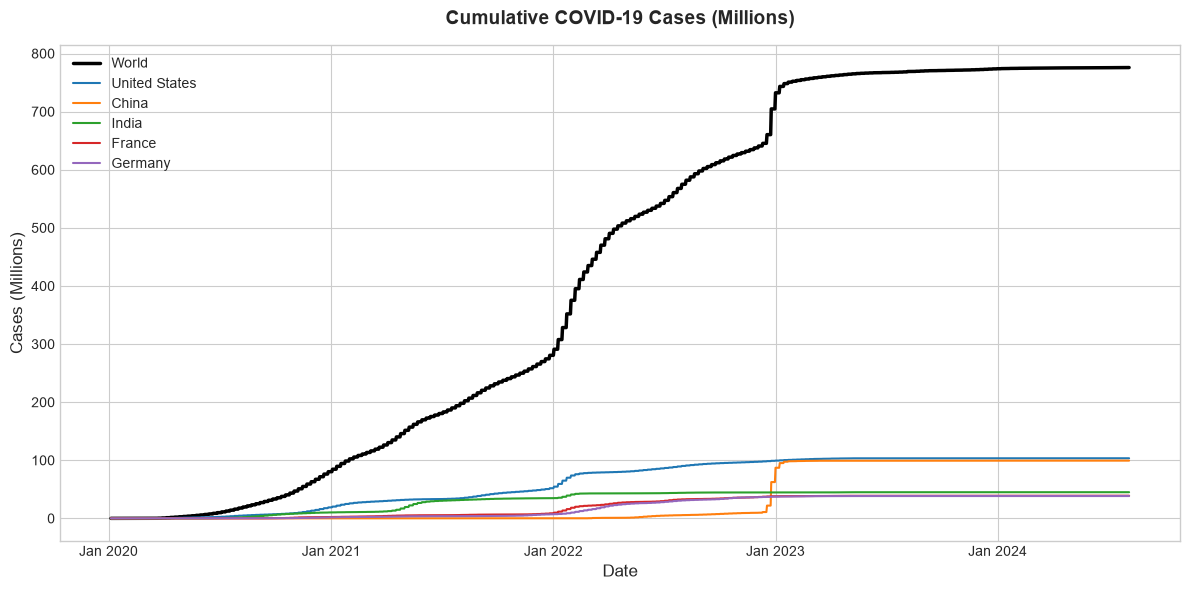

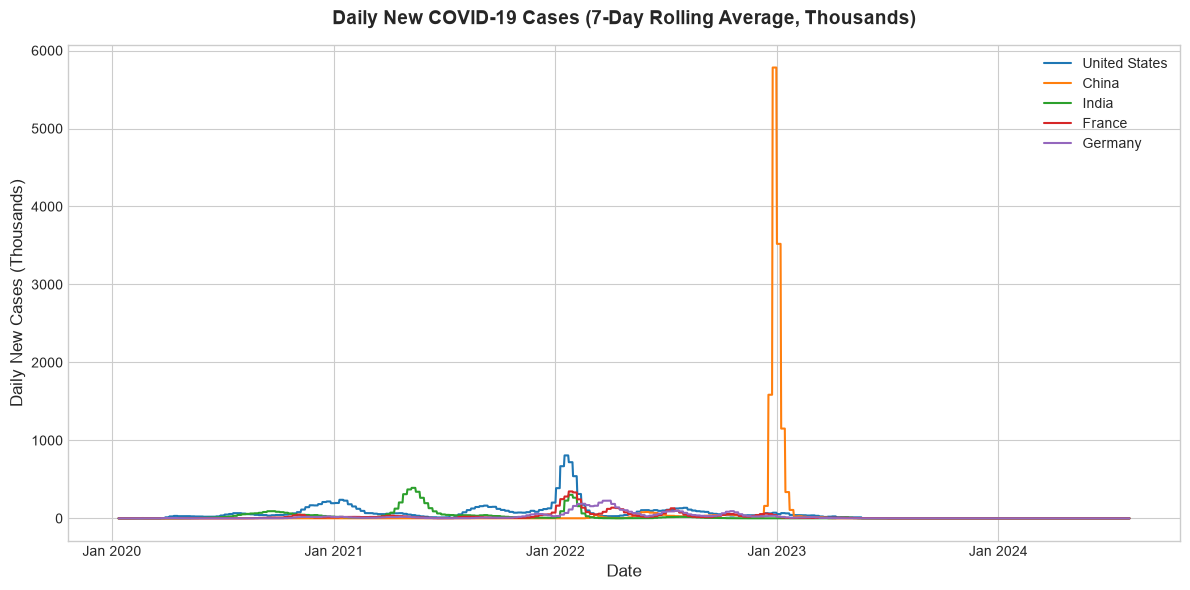

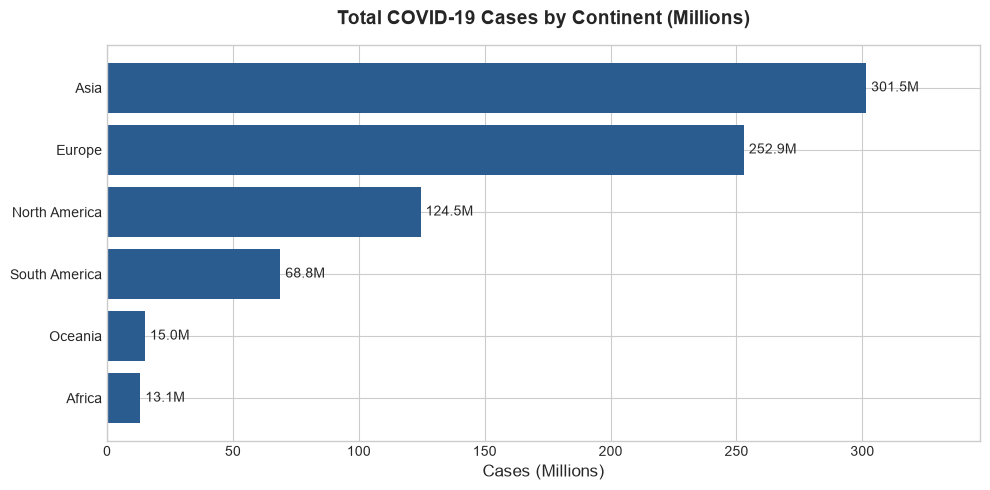

In [7]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Calculate daily new cases for World and Top 5 countries
df_daily = df.copy()
numeric_cols = [c for c in df.columns if c != 'date']
df_daily[numeric_cols] = df_daily[numeric_cols].diff().clip(lower=0) # ensure no negative values from reporting adjustments

# 7-day rolling average for smooth plotting
df_rolling = df_daily.copy()
df_rolling[numeric_cols] = df_rolling[numeric_cols].rolling(window=7).mean()

# Figure 1: Cumulative Cases Over Time (World and Top 5 Countries)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.figure(figsize=(12, 6))
plt.plot(df['date'], df['World'] / 1e6, label='World', color='black', linewidth=2.5)
top5 = latest_top10_countries.index[:5]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
for country, col in zip(top5, colors):
    plt.plot(df['date'], df[country] / 1e6, label=country, linewidth=1.5, color=col)

plt.title('Cumulative COVID-19 Cases (Millions)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Cases (Millions)', fontsize=12)
plt.legend(fontsize=10, loc='upper left')
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.tight_layout()

# Figure 2: Daily New Cases (7-day rolling average) for Top 5 Countries
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.figure(figsize=(12, 6))
for country, col in zip(top5, colors):
    plt.plot(df_rolling['date'], df_rolling[country] / 1e3, label=country, linewidth=1.5, color=col)

plt.title('Daily New COVID-19 Cases (7-Day Rolling Average, Thousands)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Daily New Cases (Thousands)', fontsize=12)
plt.legend(fontsize=10, loc='upper right')
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.tight_layout()

# Figure 3: Regional Distribution Bar Chart
plt.figure(figsize=(10, 5))
regional_data = latest_row[['Asia', 'Europe', 'North America', 'South America', 'Oceania', 'Africa']].sort_values(ascending=True)
bars = plt.barh(regional_data.index, regional_data.values / 1e6, color='#2b5c8f')
plt.title('Total COVID-19 Cases by Continent (Millions)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Cases (Millions)', fontsize=12)
for bar in bars:
    width = bar.get_width()
    plt.text(width + 2, bar.get_y() + bar.get_height()/2, f'{width:.1f}M', ha='left', va='center', fontsize=10)
plt.xlim(0, max(regional_data.values / 1e6) * 1.15)
plt.tight_layout()


In [8]:
# Save processed data as a CSV
df_processed = df.copy()
df_processed.to_csv('processed_covid_cases.csv', index=False)